# Final reproduction run

This notebook tests the Dream2Learn mechanism using the selected **balanced residual conditional VAE** with a 128-dimensional latent. The same seed-42 task-0 checkpoint initializes all conditions, so later differences isolate replay, random latent augmentation, and directed latent dreaming. The run is resumable at every task boundary.

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

from src import Config, default_device, load_run, run_experiment

SEED = 42
OUTPUT_DIR = Path('outputs')
BASE_CHECKPOINT = OUTPUT_DIR / 'phase7_experiment5_balanced_latent128_selected_seed-42.pt'
RESULT_OUTPUT = OUTPUT_DIR / 'phase8_final_balanced_mechanism_seed-42.json'
MODES = ('replay_only', 'random_dreams', 'directed_with_reuse')
DEVICE = default_device()

cfg = Config(
    data_root=Path('data'), output_dir=OUTPUT_DIR, seed=SEED,
    base_classes=50, classes_per_task=5, num_tasks=11,
    image_size=84, model_variant='balanced', latent_dim=128,
    condition_dim=16, batch_size=32, num_workers=0,
    base_epochs=20, incremental_epochs=10, dream_epochs=2,
    learning_rate=3e-4, weight_decay=1e-4,
    replay_size=2000, reconstruction_weight=1.0, kl_weight=1e-3,
    dream_weight=1.0, dream_steps=200, dream_learning_rate=0.02,
    validation_samples_per_class=50,
)

if not BASE_CHECKPOINT.is_file():
    raise FileNotFoundError(f'Run Experiment 5 first; missing {BASE_CHECKPOINT}.')
BASE_SHA256 = hashlib.sha256(BASE_CHECKPOINT.read_bytes()).hexdigest()
print(f'device={DEVICE}; seed={SEED}; modes={MODES}')
print(f'improved base={BASE_CHECKPOINT} ({BASE_SHA256[:12]}...)')

device=mps; seed=42; modes=('replay_only', 'random_dreams', 'directed_with_reuse')
improved base=outputs/phase7_experiment5_balanced_latent128_selected_seed-42.pt (e2cb888d9722...)


## Protocol

- The selected 100-epoch balanced task-0 model is shared by all three conditions; redundant task-0 retraining is skipped.
- Each condition still receives the same two post-base epochs, ten real/replay epochs plus two post-dream epochs on incremental tasks, replay capacity 2,000, task stream, and optimizer configuration.
- `replay_only` is the matched rehearsal baseline. `random_dreams` controls for auxiliary latent augmentation and slot reuse. `directed_with_reuse` is the proposed mechanism.
- Full-head FWT follows the paper's broad definition: incoming-task accuracy immediately before learning minus a measured randomly initialized reference. Because slot assignment uses incoming training labels and our output head differs from the paper, it is reported as similar rather than exactly equivalent. Task-restricted FWT is retained as an additional diagnostic.
- Test results are read only after the protocol has been fixed. Run this cell again after interruption to resume from the newest matching task-boundary checkpoint.

In [2]:
def matching_run(mode: str) -> Path | None:
    root = OUTPUT_DIR / mode / f'seed-{SEED}'
    if not root.exists():
        return None
    for candidate in sorted(root.iterdir(), reverse=True):
        checkpoint = candidate / 'checkpoint.pt'
        if not checkpoint.is_file():
            continue
        state = torch.load(checkpoint, map_location='cpu', weights_only=False)
        base = state.get('base_model') or {}
        if (
            state.get('mode') == mode
            and state.get('config') == cfg.to_dict()
            and base.get('sha256') == BASE_SHA256
        ):
            return candidate
    return None


def json_safe(value):
    if isinstance(value, np.ndarray):
        return [json_safe(item) for item in value.tolist()]
    if isinstance(value, float) and not np.isfinite(value):
        return None
    if isinstance(value, dict):
        return {key: json_safe(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(item) for item in value]
    return value


def save_summary(completed: dict) -> None:
    rows = {
        mode: {
            'run_dir': str(result.run_dir),
            'metrics': result.metrics,
            'accuracy_matrix': result.accuracy_matrix,
            'transfer': result.transfer,
        }
        for mode, result in completed.items()
    }
    if 'replay_only' in rows:
        baseline = rows['replay_only']['metrics']
        for mode, row in rows.items():
            row['minus_replay'] = {
                key: row['metrics'][key] - baseline[key] for key in baseline
            }
    if 'random_dreams' in rows and 'directed_with_reuse' in rows:
        random_metrics = rows['random_dreams']['metrics']
        directed_metrics = rows['directed_with_reuse']['metrics']
        directed_minus_random = {
            key: directed_metrics[key] - random_metrics[key] for key in random_metrics
        }
    else:
        directed_minus_random = None
    payload = {
        'protocol': {
            'seed': SEED,
            'modes': list(MODES),
            'config': cfg.to_dict(),
            'base_checkpoint': str(BASE_CHECKPOINT),
            'base_sha256': BASE_SHA256,
            'base_checkpoint_epoch': 100,
        },
        'conditions': rows,
        'directed_minus_random': directed_minus_random,
    }
    temporary = RESULT_OUTPUT.with_suffix('.json.tmp')
    temporary.write_text(json.dumps(json_safe(payload), indent=2, allow_nan=False), encoding='utf-8')
    temporary.replace(RESULT_OUTPUT)


results = {}
for mode in MODES:
    existing = matching_run(mode)
    if existing is not None:
        saved = torch.load(existing / 'checkpoint.pt', map_location='cpu', weights_only=False)
        if saved['next_task'] == cfg.num_tasks:
            print(f'[{mode}] loading completed run {existing}')
            result = load_run(existing, device=DEVICE)
        else:
            print(f'[{mode}] resuming task {saved["next_task"]} from {existing}')
            result = run_experiment(
                cfg, mode=mode, device=DEVICE, resume_from=existing,
                base_model_checkpoint=BASE_CHECKPOINT,
            )
    else:
        result = run_experiment(
            cfg, mode=mode, device=DEVICE,
            base_model_checkpoint=BASE_CHECKPOINT,
        )
    results[mode] = result
    save_summary(results)
    print(f'[{mode}] complete: {result.metrics}')

print(f'Saved final summary to {RESULT_OUTPUT}')

[setup] replay_only, device=mps, run=outputs/replay_only/seed-42/20261027T192320Z-3ed3ad53
[task_0/dream_training] 1/2 loss=0.9469 CE=0.6470 rec=0.0889 KL=12.1281 dream=0.0000 time=150.9s
[task_0/dream_training] 2/2 loss=0.8546 CE=0.6423 rec=0.0891 KL=11.8014 dream=0.0000 time=150.7s
[task 0] seen accuracy=[0.6486]
[task_1/real] 1/10 loss=4.1700 CE=2.4421 rec=0.1099 KL=12.7091 dream=0.0000 time=16.7s
[task_1/real] 2/10 loss=1.9762 CE=1.1766 rec=0.1054 KL=12.2267 dream=0.0000 time=15.3s
[task_1/real] 3/10 loss=1.2458 CE=0.7549 rec=0.1030 KL=11.7737 dream=0.0000 time=15.3s
[task_1/real] 4/10 loss=1.0223 CE=0.6565 rec=0.1019 KL=11.8616 dream=0.0000 time=15.1s
[task_1/real] 5/10 loss=0.8480 CE=0.5297 rec=0.1021 KL=12.2985 dream=0.0000 time=14.9s
[task_1/real] 6/10 loss=0.7981 CE=0.5231 rec=0.1014 KL=12.5024 dream=0.0000 time=14.8s
[task_1/real] 7/10 loss=0.7231 CE=0.4656 rec=0.1009 KL=12.5166 dream=0.0000 time=14.7s
[task_1/real] 8/10 loss=0.6604 CE=0.4190 rec=0.1001 KL=12.5577 dream=0.000

/Users/ipfilidzhade/Projects/masters/cv/d2l_reproduction/src/visualization.py:72: UserWarning: linalg.svd: matrix too large to stage in MPS threadgroup memory (140288 > 32768 bytes); falling back to CPU. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/native/mps/operations/LinearAlgebra.mm:1937.)
  _, _, components = torch.linalg.svd(centered, full_matrices=False)


[task 0] seen accuracy=[0.6308]
[task_1/real] 1/10 loss=8.0004 CE=1.8065 rec=0.1077 KL=7.3117 dream=5.0965 time=14.8s
[task_1/real] 2/10 loss=7.4282 CE=1.3223 rec=0.1016 KL=7.7027 dream=5.1777 time=14.7s
[task_1/real] 3/10 loss=7.2002 CE=1.2080 rec=0.1019 KL=7.6583 dream=5.1489 time=15.0s
[task_1/real] 4/10 loss=7.0690 CE=1.1448 rec=0.1012 KL=7.6421 dream=5.1349 time=14.8s
[task_1/real] 5/10 loss=6.9599 CE=1.0741 rec=0.1017 KL=7.7838 dream=5.1155 time=14.8s
[task_1/real] 6/10 loss=6.9314 CE=1.0534 rec=0.1019 KL=7.6919 dream=5.1166 time=14.3s
[task_1/real] 7/10 loss=6.9252 CE=1.0365 rec=0.1019 KL=7.6375 dream=5.1303 time=14.4s
[task_1/real] 8/10 loss=6.8907 CE=0.9896 rec=0.1012 KL=7.5974 dream=5.1409 time=14.6s
[task_1/real] 9/10 loss=6.9561 CE=0.9727 rec=0.1015 KL=7.6938 dream=5.1776 time=14.8s
[task_1/real] 10/10 loss=6.8989 CE=0.9603 rec=0.1015 KL=7.4179 dream=5.1480 time=14.3s
[task_1/dream_training] 1/2 loss=6.8473 CE=0.9153 rec=0.1016 KL=7.3696 dream=5.1423 time=14.2s
[task_1/drea

All values below are percentages or percentage-point differences.
Condition                  Final average accuracy Sample-weighted accuracy       Average forgetting            Full-head FWT      Task-restricted FWT
replay_only                                22.06%                   13.88%                   70.22%                   -1.08%                    1.60%
random_dreams                              23.06%                   19.12%                   70.18%                   -2.14%                    1.64%
directed_with_reuse                        19.76%                   14.17%                   71.99%                    4.44%                    1.96%

Directed minus replay:
  Final average accuracy: -2.30 pp
  Sample-weighted accuracy: +0.29 pp
  Average forgetting: +1.77 pp
  Full-head FWT: +5.52 pp
  Task-restricted FWT: +0.36 pp
Directed minus random dreams:
  Final average accuracy: -3.31 pp
  Sample-weighted accuracy: -4.95 pp
  Average forgetting: +1.81 pp
  Full-head FWT:

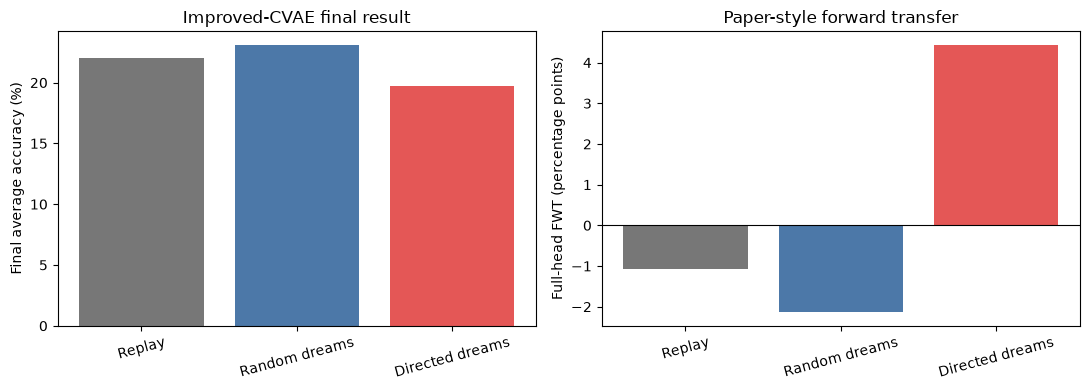

Saved report figure to docs/report/final-balanced-results.png


In [3]:
metric_labels = {
    'final_average_accuracy': 'Final average accuracy',
    'final_sample_weighted_accuracy': 'Sample-weighted accuracy',
    'average_forgetting': 'Average forgetting',
    'forward_transfer_full_head': 'Full-head FWT',
    'forward_transfer_task_restricted': 'Task-restricted FWT',
}

print('All values below are percentages or percentage-point differences.')
header = f'{"Condition":<24}' + ''.join(f'{label:>25}' for label in metric_labels.values())
print(header)
for mode in MODES:
    metrics = results[mode].metrics
    print(f'{mode:<24}' + ''.join(f'{100 * metrics[key]:>24.2f}%' for key in metric_labels))

directed = results['directed_with_reuse'].metrics
random_control = results['random_dreams'].metrics
replay = results['replay_only'].metrics
print('\nDirected minus replay:')
for key, label in metric_labels.items():
    print(f'  {label}: {100 * (directed[key] - replay[key]):+.2f} pp')
print('Directed minus random dreams:')
for key, label in metric_labels.items():
    print(f'  {label}: {100 * (directed[key] - random_control[key]):+.2f} pp')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
names = ['Replay', 'Random dreams', 'Directed dreams']
colors = ['#777777', '#4c78a8', '#e45756']
accuracy = [100 * results[mode].metrics['final_average_accuracy'] for mode in MODES]
fwt = [100 * results[mode].metrics['forward_transfer_full_head'] for mode in MODES]
axes[0].bar(names, accuracy, color=colors)
axes[0].set_ylabel('Final average accuracy (%)')
axes[0].set_title('Improved-CVAE final result')
axes[1].bar(names, fwt, color=colors)
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_ylabel('Full-head FWT (percentage points)')
axes[1].set_title('Paper-style forward transfer')
for axis in axes:
    axis.tick_params(axis='x', rotation=15)
fig.tight_layout()
figure_path = Path('docs/report/final-balanced-results.png')
fig.savefig(figure_path, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved report figure to {figure_path}')

## Interpretation gate

The directed mechanism supports the reproduced claim only if it improves final average accuracy over both replay-only and random dreams. FWT is secondary: report its sign and scale, but do not treat task-restricted FWT as equivalent to the paper's full-head metric. A directed-versus-random failure indicates that any benefit is explained better by auxiliary latent augmentation or slot reuse than by directed dreaming.